[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch06_Lab07_Loss_Functions_with_outputs.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 6: Loss Functions: Every One, and When** (Part II: Making It Learn).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=6](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=6)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab 07 — Loss Functions

**Neural Networks & Deep Learning Lab · 2026**
*Follows Lab 05 (Activation Functions)*

---

### Why this lab exists

Lab 05 ended on a decision table: the task picks the output activation. This lab
finishes that sentence — **the task picks the output activation *and* the loss,
and they are chosen together.** Sigmoid without cross-entropy is a different,
worse model than sigmoid with it, and §8 measures exactly how much worse.

A loss function is not a scorecard bolted on at the end. It is the **only place
your opinion about the data enters the optimisation**:

- it declares what counts as an error (a 10-unit miss vs ten 1-unit misses),
- it declares what the network should converge to (the mean? the median? a
  calibrated probability? a margin?),
- and through $\partial\mathcal{L}/\partial z$ it *is* the first term of every
  backprop chain you wrote by hand in Lab 03.

Change the loss and you change the answer — even with the same architecture, the
same data, and the same number of epochs.

### Learning outcomes

By the end you will be able to:

1. Write each loss and its derivative, and say what **distribution** it assumes.
2. Predict, before training, whether a loss will converge to the **mean, the
   median, or a quantile** — and verify it numerically.
3. Explain why **MSE with a sigmoid output is a bug**, and quantify the gradient
   you lose.
4. Choose between cross-entropy, hinge and focal loss on stated grounds —
   calibration, margin, or class imbalance.
5. Diagnose a training run from the loss alone: outlier domination, saturation,
   a majority class swallowing the gradient.

### Contents

| § | Topic | Key artefact |
|---|-------|--------------|
| 1 | What a loss *is* — three views | distribution → loss table |
| 2 | **The minimiser test** | MSE→mean, MAE→median, pinball→quantile, verified |
| 3 | **MSE** — the default | quadratic penalty, outlier pull |
| 4 | **MAE** — the robust one | constant gradient, the kink at 0 |
| 5 | **Huber / log-cosh** | δ sweep, the hybrid |
| 6 | Regression head-to-head | four fits, one outlier |
| 7 | **Binary cross-entropy** | Bernoulli MLE, the $-\log p$ cliff |
| 8 | **Why MSE + sigmoid is a bug** | 400× gradient loss, measured |
| 9 | **Categorical CE**, sparse CE, label smoothing | one-hot, soft targets |
| 10 | **KL divergence** vs CE | $H(p)$ is a constant — until it isn't |
| 11 | **Hinge** — the margin loss | hinge vs logistic vs 0–1 |
| 12 | **Focal loss** — class imbalance | γ sweep, PR curves: ranking vs threshold |
| 13 | Decision guide | cheat sheet |
| 14 | Exercises | — |

> **How to run:** top to bottom, `Runtime → Run all`. NumPy + Matplotlib + SciPy +
> scikit-learn. No GPU, no downloads, ~20 s total.

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * The notebook called the activation-functions lab "Lab 04"; it is **Lab 05** (`Lab05_2026_Activation_Functions_with_outputs.ipynb`). All 12 references now say Lab 05; the section numbers they cite were already right.
> * Exercise E7 pointed at a "Lab 06" that does not exist; it now names the CIFAR-10 notebook.
> * Decision guide: for counts with Poisson loss the output is now **exp or softplus, not ReLU**. Poisson loss takes log ŷ, and a ReLU output can be exactly 0.
> * §12.3 said the logistic regression "already fits its data perfectly"; its average precision is about 0.33. The sentence now gives the real reason focal loss cannot help there.

## 0 · Setup

One cell: imports, a fixed colour per loss (held for the whole notebook so a
curve's identity never changes between plots), and every loss with its analytic
derivative.

Note `bce_from_logits` — computing BCE from the **logit** rather than from the
probability, using the same `log-sum-exp` trick you met in Lab 05 §5.3. This is
what `from_logits=True` does for you.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=4, suppress=True, linewidth=110)

# ---------------------------------------------------------------- palette ---
C = {
    'mse':    '#2a78d6',   # blue    — also cross-entropy in the classification half
    'mae':    '#eb6834',   # orange  — also hinge
    'huber':  '#1baf7a',   # aqua    — also focal
    'logcosh':'#4a3aa7',   # violet  — also KL
}
C['ce'], C['hinge'], C['focal'], C['kl'] = C['mse'], C['mae'], C['huber'], C['logcosh']
GRID, INK, MUTE, BAD = '#e6e5e1', '#0b0b0b', '#52514e', '#e34948'

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': MUTE, 'axes.labelcolor': INK, 'axes.titlecolor': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'xtick.color': MUTE, 'ytick.color': MUTE,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'legend.frameon': False, 'lines.linewidth': 2.0,
})

def style(ax, title=None, xlabel=None, ylabel=None, zero=True):
    if title:  ax.set_title(title, loc='left', pad=8)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if zero:
        ax.axhline(0, color=MUTE, lw=0.8, zorder=1)
        ax.axvline(0, color=MUTE, lw=0.8, zorder=1)
    return ax

# ------------------------------------------------- regression losses (r = y_hat - y)
def mse(r):      return 0.5 * r ** 2                 # 1/2 keeps the derivative clean
def d_mse(r):    return r

def mae(r):      return np.abs(r)
def d_mae(r):    return np.sign(r)                   # undefined at 0; convention: 0

def huber(r, d=1.0):
    a = np.abs(r)
    return np.where(a <= d, 0.5 * r ** 2, d * (a - 0.5 * d))
def d_huber(r, d=1.0):
    return np.clip(r, -d, d)                         # that is the whole derivative

def logcosh(r):  return np.log(np.cosh(r))
def d_logcosh(r):return np.tanh(r)                   # bounded, smooth everywhere

def pinball(r, tau=0.5):
    # quantile / pinball loss, written for r = pred - y.
    # under-predicting (r<0) costs tau; over-predicting (r>0) costs 1-tau,
    # so a large tau pushes the prediction UP, towards the upper quantile.
    return np.where(r <= 0, -tau * r, (1.0 - tau) * r)

# --------------------------------------------- classification losses (p = prob)
EPS = 1e-12
def sigmoid(x):
    x = np.asarray(x, dtype=float)
    out = np.empty_like(x)
    pos = x >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-x[pos]))
    ex = np.exp(x[~pos]); out[~pos] = ex / (1.0 + ex)
    return out

def softmax(z, axis=-1):
    z = np.asarray(z, dtype=float)
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def bce(p, y):                                       # y in {0, 1}
    p = np.clip(p, EPS, 1 - EPS)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def bce_from_logits(z, y):
    # stable: log(1 + e^-|z|) + max(z, 0) - z*y   -- never overflows
    return np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0) - z * y

def cce(p, y_onehot, axis=-1):
    return -(y_onehot * np.log(np.clip(p, EPS, 1.0))).sum(axis=axis)

def hinge(m):    return np.maximum(0.0, 1.0 - m)     # m = margin = y*f(x), y in {-1,+1}
def sq_hinge(m): return np.maximum(0.0, 1.0 - m) ** 2

def focal(p_t, gamma=2.0, alpha=1.0):                # p_t = prob of the TRUE class
    p_t = np.clip(p_t, EPS, 1.0)
    return -alpha * (1 - p_t) ** gamma * np.log(p_t)

R = np.linspace(-4, 4, 1601)        # residual grid
P = np.linspace(1e-4, 1 - 1e-4, 2000)   # probability grid
print('setup complete ·', 'numpy', np.__version__)

setup complete · numpy 2.4.6


---
## 1 · What a loss function actually is

### 1.1 Three views, all the same object

**View A — a number to minimise.** The naive view. True, and almost useless for
choosing one.

**View B — a probabilistic assumption.** Nearly every standard loss is the
**negative log-likelihood** of an assumed model of the labels:

$$\mathcal{L} = -\log p(y \mid \hat{y})$$

| Assumed label distribution | Negative log-likelihood | Loss you know it as |
|---|---|---|
| Gaussian, fixed σ | $\frac{(y-\hat y)^2}{2\sigma^2} + \text{const}$ | **MSE** |
| Laplace | $\frac{|y-\hat y|}{b} + \text{const}$ | **MAE** |
| Bernoulli | $-[y\log p + (1-y)\log(1-p)]$ | **binary cross-entropy** |
| Categorical | $-\sum_i y_i \log p_i$ | **categorical cross-entropy** |
| Poisson | $\hat y - y\log\hat y + \text{const}$ | **Poisson loss** (counts) |

This is the view that answers *"which loss?"* — **you are choosing a noise model.**
Using MSE says "my errors are Gaussian, so a 10-unit miss is 100× worse than a
1-unit miss." Using MAE says "my errors are Laplace — heavy tails, outliers are
expected, don't over-react."

**View C — the first link of the backprop chain.** From Lab 03:

$$\frac{\partial \mathcal{L}}{\partial W_L} = \underbrace{\frac{\partial \mathcal{L}}{\partial \hat y}}_{\text{the loss}} \cdot \frac{\partial \hat y}{\partial z_L} \cdot \frac{\partial z_L}{\partial W_L}$$

The loss supplies the very first factor. If it is small where you are wrong, you
do not learn — which is the whole of §8.

### 1.2 The one-line test

> **Look at the derivative, not the loss.** The loss curve is what you report;
> the derivative curve is what the network actually feels.

Keep that in view: every section below plots both.

In [2]:
# --- 1.1 "Loss = negative log-likelihood" is literal, not an analogy ---------
rng = np.random.default_rng(0)
y    = rng.normal(5.0, 2.0, size=200)          # observations
grid = np.linspace(3.5, 6.5, 601)              # candidate predictions

sigma = 2.0
nll_gauss = np.array([(-np.log(1 / (np.sqrt(2 * np.pi) * sigma)) +
                       ((y - c) ** 2) / (2 * sigma ** 2)).sum() for c in grid])
sse       = np.array([((y - c) ** 2).sum() for c in grid])

b = 1.0
nll_lap = np.array([(np.log(2 * b) + np.abs(y - c) / b).sum() for c in grid])
sae     = np.array([np.abs(y - c).sum() for c in grid])

print('argmin of Gaussian NLL :', f'{grid[nll_gauss.argmin()]:.4f}')
print('argmin of sum-sq-error :', f'{grid[sse.argmin()]:.4f}   <- same point')
print('argmin of Laplace  NLL :', f'{grid[nll_lap.argmin()]:.4f}')
print('argmin of sum-abs-error:', f'{grid[sae.argmin()]:.4f}   <- same point')
print()
# the two differ only by an affine transform, which cannot move an argmin
a, k = np.polyfit(sse, nll_gauss, 1)
print(f'Gaussian NLL = {a:.6f} * SSE + {k:.4f}   (an affine map of MSE)')
print('correlation:', np.corrcoef(sse, nll_gauss)[0, 1])

argmin of Gaussian NLL : 5.0300
argmin of sum-sq-error : 5.0300   <- same point
argmin of Laplace  NLL : 5.0950
argmin of sum-abs-error: 5.0950   <- same point

Gaussian NLL = 0.125000 * SSE + 322.4171   (an affine map of MSE)
correlation: 1.0


---
## 2 · The minimiser test — *the* idea in this lab

Before asking "which loss trains better", ask a sharper question:

> **If the model could output any constant it liked, what would each loss drive
> it to?**

The answers are exact, classical, and different:

$$\arg\min_c \;\mathbb{E}\big[(y-c)^2\big] = \mathbb{E}[y] \;\;\textbf{(the mean)}$$

$$\arg\min_c \;\mathbb{E}\big[|y-c|\big] = \mathrm{median}(y) \;\;\textbf{(the median)}$$

$$\arg\min_c \;\mathbb{E}\big[\rho_\tau(y-c)\big] = Q_\tau(y) \;\;\textbf{(the }\tau\text{-quantile)}$$

where $\rho_\tau$ is the **pinball loss** $\rho_\tau(r) = \max(\tau r,\,(\tau-1)r)$.

**Why this settles most arguments.** On a **skewed** target — delivery times,
house prices, session lengths, rainfall — the mean and the median are genuinely
different numbers. Train with MSE and your model predicts the mean; train with
MAE and it predicts the median. Neither is "wrong"; they are answers to
different questions. If the business asks *"what is the typical delivery time"*,
MSE answers the wrong one.

Run the cell: same data, three losses, three different optima.

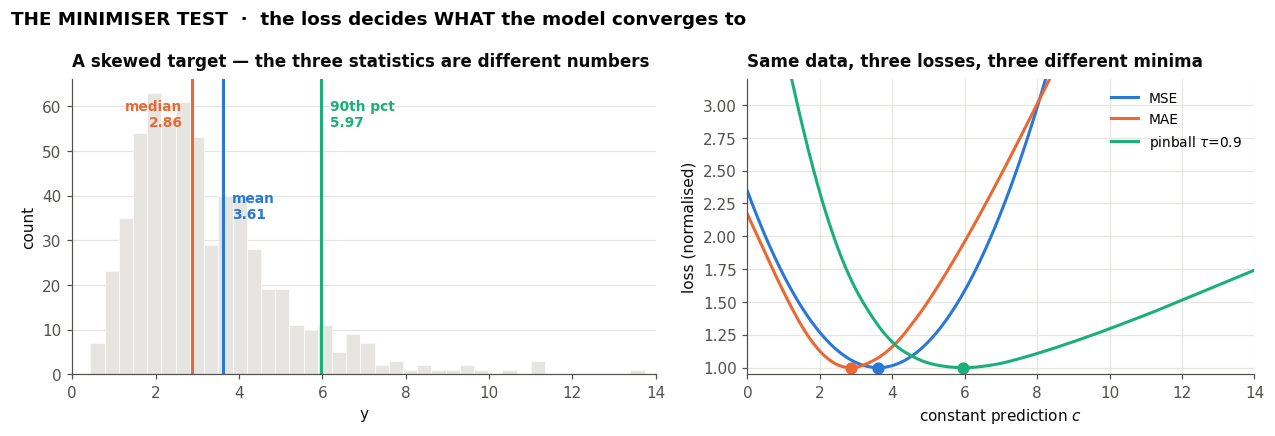

             closed form   argmin of loss
      mean        3.6141           3.6138
    median        2.8660           2.8644
  90th pct        5.9665           5.9670

mean - median = +0.748  (+26.1% apart) — on skewed data the choice of loss is a choice of answer.


In [3]:
# --- 2.1 Each loss drives the prediction to a different statistic -----------
rng = np.random.default_rng(3)
y = np.concatenate([rng.lognormal(mean=1.0, sigma=0.55, size=600),   # skewed bulk
                    rng.uniform(18, 26, size=12)])                    # a few big ones

c_grid = np.linspace(0, 14, 2000)
L_mse  = np.array([np.mean((c - y) ** 2) for c in c_grid])
L_mae  = np.array([np.mean(np.abs(c - y)) for c in c_grid])
L_q90  = np.array([np.mean(pinball(c - y, tau=0.90)) for c in c_grid])

stats = {'mean':          (np.mean(y),                c_grid[L_mse.argmin()], C['mse']),
         'median':        (np.median(y),              c_grid[L_mae.argmin()], C['mae']),
         '90th pct':      (np.quantile(y, 0.90),      c_grid[L_q90.argmin()], C['huber'])}

fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.0), gridspec_kw={'width_ratios': [1.15, 1]})
ax[0].hist(y, bins=70, color=GRID, edgecolor='white', linewidth=.4)
ytop = ax[0].get_ylim()[1]
for (name, (true, found, col)), yf, ha in zip(stats.items(), [.62, .93, .93], ['left', 'right', 'left']):
    ax[0].axvline(found, color=col, lw=2)
    ax[0].annotate(f'{name}\n{found:.2f}', (found + (.22 if ha == 'left' else -.22), ytop * yf),
                   color=col, fontsize=9, fontweight='bold', ha=ha, va='top')
ax[0].set_xlim(0, 14); ax[0].grid(axis='x', visible=False)
style(ax[0], 'A skewed target — the three statistics are different numbers',
      xlabel='y', ylabel='count', zero=False)

for (lab, arr, col) in [('MSE', L_mse / L_mse.min(), C['mse']),
                        ('MAE', L_mae / L_mae.min(), C['mae']),
                        ('pinball $\\tau$=0.9', L_q90 / L_q90.min(), C['huber'])]:
    ax[1].plot(c_grid, arr, color=col, label=lab)
    ax[1].plot(c_grid[arr.argmin()], arr.min(), 'o', ms=7, color=col)
ax[1].set_ylim(.95, 3.2); ax[1].set_xlim(0, 14); ax[1].legend(fontsize=9)
style(ax[1], 'Same data, three losses, three different minima',
      xlabel='constant prediction $c$', ylabel='loss (normalised)', zero=False)
fig.suptitle('THE MINIMISER TEST  ·  the loss decides WHAT the model converges to',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f'{"":>10}{"closed form":>14}{"argmin of loss":>17}')
for name, (true, found, _) in stats.items():
    print(f'{name:>10}{true:>14.4f}{found:>17.4f}')
print(f'\nmean - median = {np.mean(y) - np.median(y):+.3f}  '
      f'({100 * (np.mean(y) / np.median(y) - 1):+.1f}% apart) — on skewed data the '
      'choice of loss is a choice of answer.')

### 2.2 What to remember

| You want the model to predict | Train with |
|---|---|
| the **conditional mean** | MSE |
| the **conditional median** (robust central value) | MAE |
| the **τ-quantile** (e.g. a 90% delivery-time promise) | pinball / quantile loss |
| a **calibrated probability** | cross-entropy |
| a **decision with margin**, calibration irrelevant | hinge |

Everything else in this lab is a refinement of this table.

> **Exam-trap.** "MAE is better because it is robust to outliers" is only half a
> sentence. MAE is robust *because* it targets the median. If the quantity you
> actually need is a mean — a total, a budget, an expected cost that must add up —
> then MAE is systematically biased and its robustness is a bug.

---
## 3 · MSE — mean squared error

$$\boxed{\;\mathcal{L}_{\text{MSE}} = \tfrac{1}{2}(\hat y - y)^2\;}\qquad
\frac{\partial\mathcal{L}}{\partial \hat y} = (\hat y - y) = r$$

*(The $\tfrac12$ is a convention that cancels in the derivative. Keras omits it;
it only rescales the learning rate.)*

### 3.1 The one property that defines it

**The gradient is proportional to the error.** Big miss → big correction; small
miss → small correction. That self-annealing behaviour is why MSE converges
smoothly and why it is the default.

The same property is its failure: the penalty is *quadratic*, so one sample that
is 10× further away contributes **100×** the loss and **10×** the gradient. A
single mislabelled point can out-vote a hundred good ones.

### 3.2 Properties

| | |
|---|---|
| Assumes | Gaussian errors, constant variance |
| Converges to | the **conditional mean** |
| Derivative | $r$ — unbounded, linear in the error |
| Units | squared (RMSE puts them back) |
| Differentiable | everywhere, smooth second derivative |
| Outliers | **dominates** — the main weakness |
| Use when | errors are roughly symmetric and outlier-free, or you genuinely want a mean |

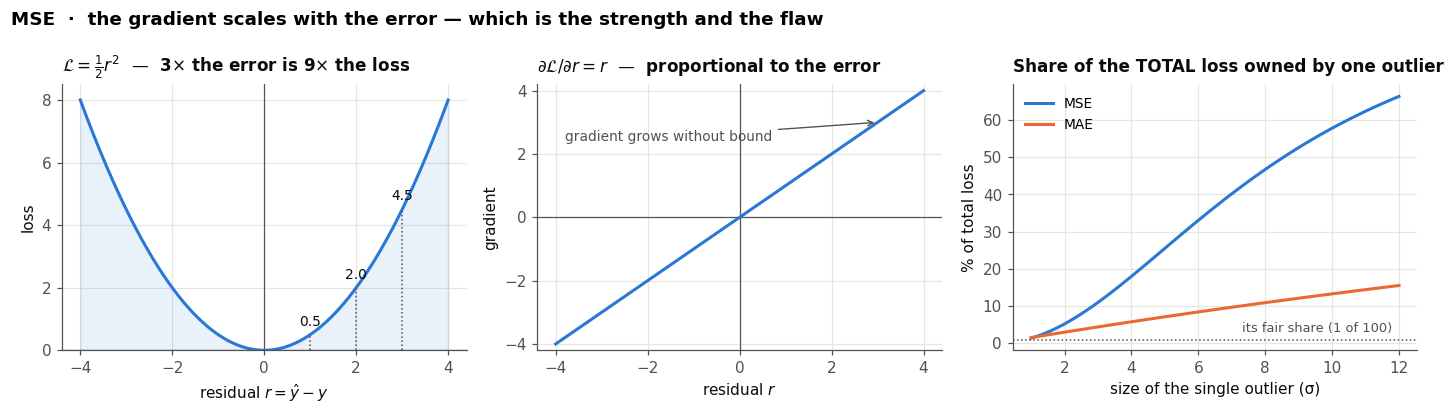

outlier at  3σ  ->  MSE: it owns  11.0% of the loss   MAE:  4.4%
outlier at  6σ  ->  MSE: it owns  33.0% of the loss   MAE:  8.4%
outlier at 10σ  ->  MSE: it owns  57.8% of the loss   MAE: 13.3%


In [4]:
# --- 3.1 MSE, its derivative, and how one outlier takes over ---------------
fig, ax = plt.subplots(1, 3, figsize=(13.0, 3.8))

ax[0].plot(R, mse(R), color=C['mse'])
ax[0].fill_between(R, 0, mse(R), color=C['mse'], alpha=.10)
for r0 in (1, 2, 3):
    ax[0].plot([r0, r0], [0, mse(r0)], color=MUTE, ls=':', lw=1)
    ax[0].annotate(f'{mse(r0):.1f}', (r0, mse(r0)), (0, 6), textcoords='offset points',
                   ha='center', fontsize=9, color=INK)
ax[0].set_ylim(0, 8.5)
style(ax[0], r'$\mathcal{L}=\frac{1}{2}r^2$  —  3$\times$ the error is 9$\times$ the loss',
      xlabel='residual $r=\\hat{y}-y$', ylabel='loss')

ax[1].plot(R, d_mse(R), color=C['mse'])
ax[1].annotate('gradient grows without bound', (3.0, 3.0), (-3.8, 2.4), color=MUTE, fontsize=9,
               arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
ax[1].set_ylim(-4.2, 4.2)
style(ax[1], r"$\partial\mathcal{L}/\partial r = r$  —  proportional to the error",
      xlabel='residual $r$', ylabel='gradient')

# how much of the total loss does the single worst point own?
rng = np.random.default_rng(1)
clean = rng.normal(0, 1.0, size=99)
shares_mse, shares_mae, out_sizes = [], [], np.linspace(1, 12, 60)
for o in out_sizes:
    res = np.append(clean, o)
    shares_mse.append(mse(res)[-1] / mse(res).sum())
    shares_mae.append(mae(res)[-1] / mae(res).sum())
ax[2].plot(out_sizes, 100 * np.array(shares_mse), color=C['mse'], label='MSE')
ax[2].plot(out_sizes, 100 * np.array(shares_mae), color=C['mae'], label='MAE')
ax[2].axhline(1, color=MUTE, ls=':', lw=1)
ax[2].annotate('its fair share (1 of 100)', (11.8, 3), color=MUTE, fontsize=8.5, ha='right')
ax[2].legend(fontsize=9)
style(ax[2], 'Share of the TOTAL loss owned by one outlier',
      xlabel='size of the single outlier (σ)', ylabel='% of total loss', zero=False)

fig.suptitle('MSE  ·  the gradient scales with the error — which is the strength and the flaw',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

for o in (3, 6, 10):
    res = np.append(clean, o)
    print(f'outlier at {o:>2}σ  ->  MSE: it owns {mse(res)[-1] / mse(res).sum():6.1%} of the loss   '
          f'MAE: {mae(res)[-1] / mae(res).sum():5.1%}')

---
## 4 · MAE — mean absolute error (L1)

$$\boxed{\;\mathcal{L}_{\text{MAE}} = |\hat y - y|\;}\qquad
\frac{\partial\mathcal{L}}{\partial \hat y} = \operatorname{sign}(r)$$

### 4.1 Constant gradient — the good news and the bad news

$|r|$ grows **linearly**, so a 10× outlier contributes 10× the loss, not 100×.
That is the robustness, and §3's third panel measured it.

But look at the derivative: it is $\pm 1$ **everywhere**. Two consequences that
students always miss:

- **Good:** an outlier's gradient is capped at 1. It cannot hijack the update.
- **Bad:** the gradient does *not* shrink as you approach the optimum. Near the
  minimum, MAE keeps taking full-size steps and **bounces around it** instead of
  settling. You must decay the learning rate; MSE anneals itself for free.
- **Also bad:** it is not differentiable at $r=0$ — exactly the point you are
  trying to reach. (Frameworks take the subgradient 0; harmless in practice, the
  same argument as ReLU at the origin in Lab 05 §4.2.)

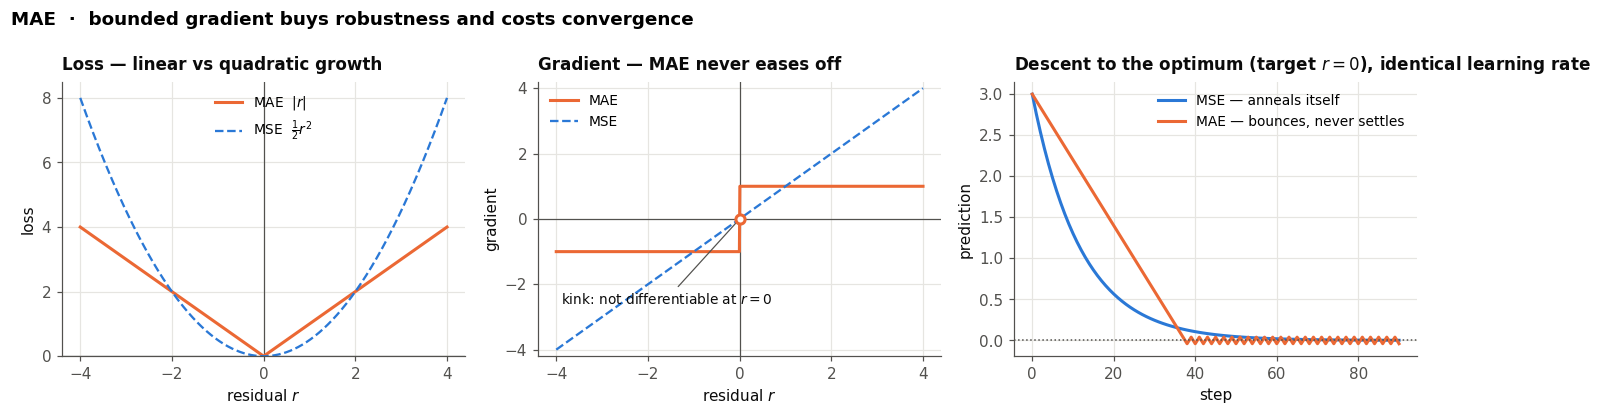

last 20 steps, |distance from optimum|:  MSE 0.00408    MAE 0.04000  <- MAE keeps overshooting


In [5]:
# --- 4.1 MAE vs MSE: loss, gradient, and behaviour near the optimum ---------
fig, ax = plt.subplots(1, 3, figsize=(13.0, 3.8))

ax[0].plot(R, mae(R), color=C['mae'], label='MAE  $|r|$')
ax[0].plot(R, mse(R), color=C['mse'], ls='--', lw=1.5, label=r'MSE  $\frac{1}{2}r^2$')
ax[0].legend(fontsize=9); ax[0].set_ylim(0, 8.5)
style(ax[0], 'Loss — linear vs quadratic growth', xlabel='residual $r$', ylabel='loss')

ax[1].plot(R, d_mae(R), color=C['mae'], label='MAE')
ax[1].plot(R, d_mse(R), color=C['mse'], ls='--', lw=1.5, label='MSE')
ax[1].plot([0], [0], 'o', ms=6, mfc='white', mec=C['mae'], mew=2, zorder=5)
ax[1].annotate('kink: not differentiable at $r=0$', (0, 0), (-3.9, -2.6), color=INK, fontsize=9,
               arrowprops=dict(arrowstyle='-', color=MUTE, lw=.8))
ax[1].legend(fontsize=9); ax[1].set_ylim(-4.2, 4.2)
style(ax[1], "Gradient — MAE never eases off", xlabel='residual $r$', ylabel='gradient')

# gradient descent on a single parameter, same lr, both losses
lr, steps = 0.08, 90
paths = {}
for key, dfn in [('mse', d_mse), ('mae', d_mae)]:
    c, p = 3.0, [3.0]
    for _ in range(steps):
        c = c - lr * dfn(np.array([c]))[0]
        p.append(c)
    paths[key] = np.array(p)
ax[2].plot(paths['mse'], color=C['mse'], label='MSE — anneals itself')
ax[2].plot(paths['mae'], color=C['mae'], label='MAE — bounces, never settles')
ax[2].axhline(0, color=MUTE, ls=':', lw=1)
ax[2].legend(fontsize=9)
style(ax[2], 'Descent to the optimum (target $r=0$), identical learning rate',
      xlabel='step', ylabel='prediction', zero=False)

fig.suptitle('MAE  ·  bounded gradient buys robustness and costs convergence',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f"last 20 steps, |distance from optimum|:  MSE {np.abs(paths['mse'][-20:]).mean():.5f}"
      f"    MAE {np.abs(paths['mae'][-20:]).mean():.5f}  <- MAE keeps overshooting")

---
## 5 · Huber and log-cosh — have both

### 5.1 Huber

$$\mathcal{L}_\delta(r)=\begin{cases}
\tfrac12 r^2 & |r|\le\delta \quad\text{(MSE inside)}\\
\delta\left(|r|-\tfrac12\delta\right) & |r|>\delta \quad\text{(MAE outside)}
\end{cases}$$

The derivative is the whole idea in one line:

$$\boxed{\;\frac{\partial\mathcal{L}_\delta}{\partial r} = \operatorname{clip}(r,\,-\delta,\,+\delta)\;}$$

**Huber is MSE with the gradient clipped.** Small residuals get the smooth,
self-annealing MSE behaviour; large ones get a capped gradient so no outlier can
dominate. The constant $-\tfrac12\delta^2$ in the outer branch exists only to make
the two pieces meet continuously in value *and* slope.

**δ is a real hyperparameter** — it is the residual size above which you stop
believing the point. Set it in the units of your target (δ = 1.0 assumes
standardised targets). Too small ⇒ pure MAE, bouncy; too large ⇒ pure MSE,
outlier-sensitive.

### 5.2 Log-cosh

$$\mathcal{L}=\log\cosh(r),\qquad \frac{\partial\mathcal{L}}{\partial r}=\tanh(r)$$

Same shape as Huber with δ=1, but **smooth everywhere** — no kink, no
hyperparameter, and a continuous second derivative (which matters if anything
downstream needs curvature). The bounded $\tanh$ derivative should look familiar
from Lab 05 §3.

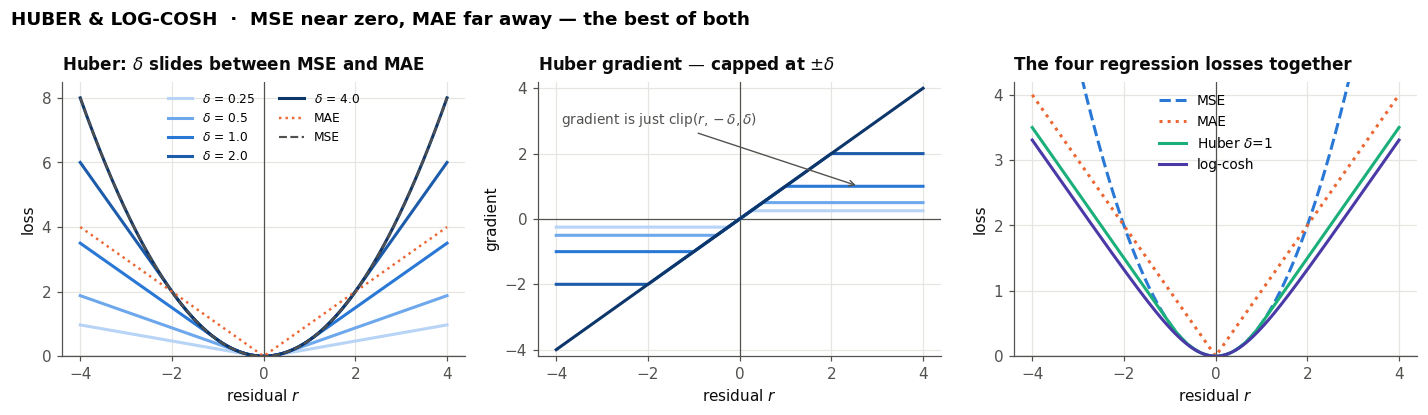

     r       MSE       MAE    Huber1   logcosh   |   gradients
   0.5     0.125     0.500     0.125     0.120   |     0.50   1.00    0.50   0.4621
   1.0     0.500     1.000     0.500     0.434   |     1.00   1.00    1.00   0.7616
   2.0     2.000     2.000     1.500     1.325   |     2.00   1.00    1.00   0.9640
   5.0    12.500     5.000     4.500     4.307   |     5.00   1.00    1.00   0.9999
  10.0    50.000    10.000     9.500     9.307   |    10.00   1.00    1.00   1.0000


In [6]:
# --- 5.1 Huber delta sweep, and the whole family on one axis ---------------
fig, ax = plt.subplots(1, 3, figsize=(13.0, 3.8))

shades = ['#b7d3f6', '#6da7ec', '#2a78d6', '#1c5cab', '#0d366b']
for d, col in zip([0.25, 0.5, 1.0, 2.0, 4.0], shades):
    ax[0].plot(R, huber(R, d), color=col, label=f'$\\delta$ = {d}')
ax[0].plot(R, mae(R), color=C['mae'], ls=':', lw=1.6, label='MAE')
ax[0].plot(R, mse(R), color=MUTE, ls='--', lw=1.4, label='MSE')
ax[0].set_ylim(0, 8.5); ax[0].legend(fontsize=8, ncol=2)
style(ax[0], r'Huber: $\delta$ slides between MSE and MAE', xlabel='residual $r$', ylabel='loss')

for d, col in zip([0.25, 0.5, 1.0, 2.0, 4.0], shades):
    ax[1].plot(R, d_huber(R, d), color=col)
ax[1].annotate(r'gradient is just $\mathrm{clip}(r,-\delta,\delta)$', (2.6, 1.0), (-3.9, 2.9),
               color=MUTE, fontsize=9, arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
ax[1].set_ylim(-4.2, 4.2)
style(ax[1], 'Huber gradient — capped at $\\pm\\delta$', xlabel='residual $r$', ylabel='gradient')

for lab, f, col, ls in [('MSE', mse, C['mse'], '--'), ('MAE', mae, C['mae'], ':'),
                        ('Huber $\\delta$=1', lambda v: huber(v, 1.0), C['huber'], '-'),
                        ('log-cosh', logcosh, C['logcosh'], '-')]:
    ax[2].plot(R, f(R), color=col, ls=ls, label=lab)
ax[2].set_ylim(0, 4.2); ax[2].legend(fontsize=9)
style(ax[2], 'The four regression losses together', xlabel='residual $r$', ylabel='loss')

fig.suptitle('HUBER & LOG-COSH  ·  MSE near zero, MAE far away — the best of both',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f'{"r":>6}{"MSE":>10}{"MAE":>10}{"Huber1":>10}{"logcosh":>10}   |   gradients')
for r0 in (0.5, 1.0, 2.0, 5.0, 10.0):
    v = np.array([r0])
    print(f'{r0:>6.1f}{mse(v)[0]:>10.3f}{mae(v)[0]:>10.3f}{huber(v)[0]:>10.3f}{logcosh(v)[0]:>10.3f}'
          f'   |   {d_mse(v)[0]:>6.2f}{d_mae(v)[0]:>7.2f}{d_huber(v)[0]:>8.2f}{d_logcosh(v)[0]:>9.4f}')

---
## 6 · Regression head-to-head — one outlier, four answers

Forty points on a clean line, plus **one** grossly wrong label. Same data, same
optimiser, only the loss differs. Watch what a single bad point does to MSE.

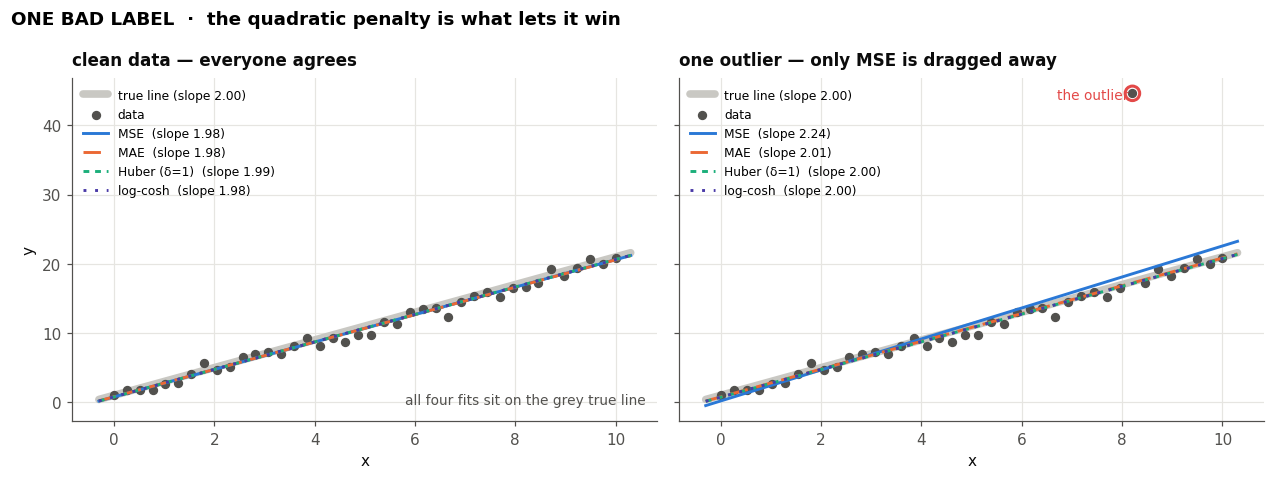

with the outlier present   (true slope 2.0, intercept 1.0)
          loss    slope  intercept   slope error
           MSE    2.239      0.190        0.239
           MAE    2.006      0.777        0.006
   Huber (δ=1)    2.002      0.731        0.002
      log-cosh    2.001      0.741        0.001


In [7]:
# --- 6.1 Fit a line under each loss, with and without one outlier ----------
rng = np.random.default_rng(7)
x = np.linspace(0, 10, 40)
TRUE_M, TRUE_B = 2.0, 1.0
y_clean = TRUE_M * x + TRUE_B + rng.normal(0, 0.8, size=x.size)
y_dirty = y_clean.copy()
y_dirty[32] += 28.0                                  # one mislabelled point

LOSSES = [('MSE',            lambda r: mse(r).mean(),              C['mse'],     '-'),
          ('MAE',            lambda r: mae(r).mean(),              C['mae'],     (0, (6, 3))),
          ('Huber (δ=1)',    lambda r: huber(r, 1.0).mean(),       C['huber'],   (0, (2, 2))),
          ('log-cosh',       lambda r: logcosh(r).mean(),          C['logcosh'], (0, (1, 3)))]

def fit(xv, yv, lossfn):
    obj = lambda p: lossfn(p[0] * xv + p[1] - yv)
    return minimize(obj, x0=[0.0, 0.0], method='Nelder-Mead',
                    options={'xatol': 1e-8, 'fatol': 1e-10, 'maxiter': 20000}).x

fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.4), sharey=True)
rows = []
for a, (yv, title) in zip(ax, [(y_clean, 'clean data — everyone agrees'),
                               (y_dirty, 'one outlier — only MSE is dragged away')]):
    xs = np.linspace(-.3, 10.3, 50)
    a.plot(xs, TRUE_M * xs + TRUE_B, color='#c9c8c3', lw=5, solid_capstyle='round',
           zorder=1, label='true line (slope 2.00)')
    a.scatter(x, yv, s=26, color=MUTE, zorder=3, label='data')
    for name, lf, col, ls in LOSSES:      # distinct dash patterns: the robust three overlap
        m, b = fit(x, yv, lf)
        a.plot(xs, m * xs + b, color=col, ls=ls, lw=1.9, zorder=4,
               label=f'{name}  (slope {m:.2f})')
        if title.startswith('one'): rows.append((name, m, b))
    a.set_title(title, loc='left', pad=8); a.set_xlabel('x'); a.legend(fontsize=8, loc='upper left')
ax[1].scatter([x[32]], [y_dirty[32]], s=90, facecolor='none', edgecolor=BAD, lw=2, zorder=5)
ax[0].text(.98, .05, 'all four fits sit on the grey true line', transform=ax[0].transAxes,
           fontsize=9, color=MUTE, ha='right')
ax[1].annotate('the outlier', (x[32], y_dirty[32]), (-2.6, -4), textcoords='offset points',
               color=BAD, fontsize=9, ha='right')
ax[0].set_ylabel('y')
fig.suptitle('ONE BAD LABEL  ·  the quadratic penalty is what lets it win',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f'with the outlier present   (true slope {TRUE_M}, intercept {TRUE_B})')
print(f'{"loss":>14}{"slope":>9}{"intercept":>11}{"slope error":>14}')
for name, m, b in rows:
    print(f'{name:>14}{m:>9.3f}{b:>11.3f}{abs(m - TRUE_M):>13.3f}')

### 6.2 Regression losses — datasheet

| | **MSE** | **MAE** | **Huber** | **log-cosh** |
|---|---|---|---|---|
| Converges to | mean | median | ≈mean (robust) | ≈mean (robust) |
| Gradient | $r$ (unbounded) | $\pm1$ (constant) | $\mathrm{clip}(r,\pm\delta)$ | $\tanh r$ |
| Outliers | **dominate** | ignored | capped at δ | capped at 1 |
| Near optimum | anneals itself | **bounces** | anneals | anneals |
| Smooth at 0 | yes | **no** | yes ($C^1$) | yes ($C^\infty$) |
| Hyperparameter | — | — | **δ** | — |
| Cost | cheapest | cheap | cheap | `log`+`cosh` |

**Choose like this**

- **MSE** — the default. Clean targets, symmetric errors, or you genuinely need a
  mean (totals, budgets, expected values). Also the only one of the four with a
  closed-form solution for linear models.
- **MAE** — noisy labels you cannot clean, heavy-tailed targets, or the median is
  the honest answer. Decay the learning rate.
- **Huber** — the practical default when you suspect outliers but still want
  smooth convergence. Set δ in target units; standardise first and δ=1 is sane.
- **log-cosh** — Huber without a hyperparameter to tune, when you want smoothness
  everywhere. Slightly more expensive, rarely a deciding factor.
- **Pinball / quantile** — you were asked for a percentile, not an average.
  Train three heads (τ = 0.1, 0.5, 0.9) and you get a prediction interval for free.

> **Do not** use a regression loss on a classification problem. That is §8.

---
## 7 · Binary cross-entropy

For a label $y\in\{0,1\}$ and a predicted probability $p$, the Bernoulli
likelihood is $p^{y}(1-p)^{1-y}$. Take $-\log$:

$$\boxed{\;\mathcal{L}_{\text{BCE}} = -\big[\,y\log p + (1-y)\log(1-p)\,\big]\;}$$

Only one term is ever active: for $y=1$ it is $-\log p$, for $y=0$ it is
$-\log(1-p)$.

### 7.1 Why the logarithm

$-\log p$ is **unbounded as $p\to 0$**. Being confidently wrong is not penalised
a bit more than being unsure — it is penalised *without limit*:

| your p when the truth is 1 | loss (nats) |
|---|---|
| 0.9 | 0.105 |
| 0.5 | 0.693 |
| 0.1 | 2.303 |
| 0.01 | 4.605 |
| 0.001 | **6.908** |

That cliff is what forces calibration. A model that hedges at 0.5 pays 0.69
forever; a model that says 0.99 and is right pays 0.01; a model that says 0.99
and is wrong pays 4.6. **Cross-entropy is the loss that makes confidence
expensive.**

### 7.2 The derivative is the point

$$\frac{\partial\mathcal{L}}{\partial p} = \frac{p-y}{p(1-p)}
\qquad\text{but through a sigmoid}\qquad
\boxed{\;\frac{\partial\mathcal{L}}{\partial z} = p - y\;}$$

The $p(1-p)$ in the denominator is **exactly** the sigmoid derivative
$\sigma'(z)$ from Lab 05 §2.1. They cancel. This is the same cancellation you saw
for softmax + categorical CE in Lab 05 §5.7, and it is not a coincidence — it is
why these pairings are canonical.

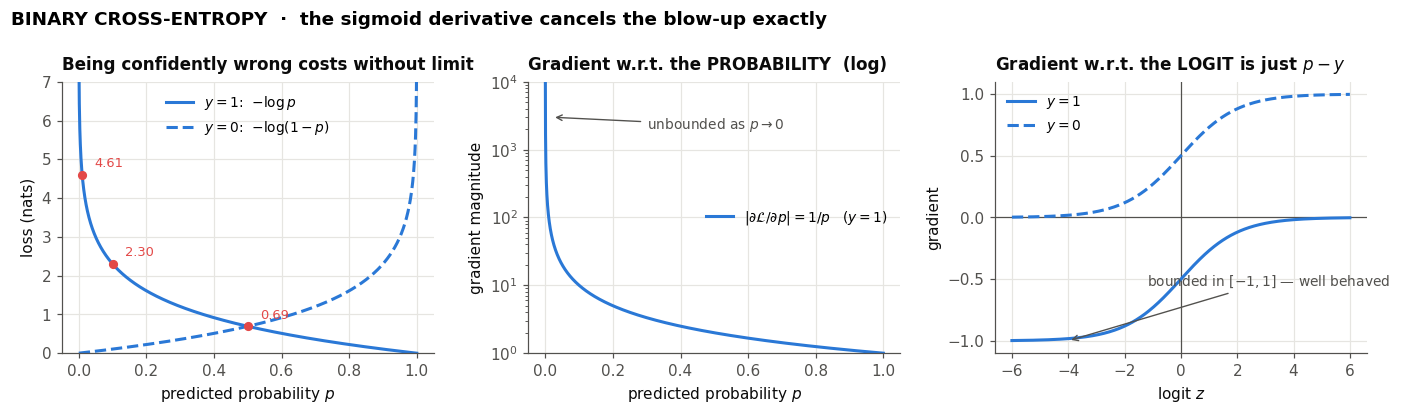

analytic p - y   = -0.154465265
finite difference= -0.154465265

stable from-logits form never overflows:
  z=    0.0  BCE(y=1) = 0.693147
  z=   50.0  BCE(y=1) = 0.000000
  z=  800.0  BCE(y=1) = 0.000000
  z= -800.0  BCE(y=1) = 800.000000


In [8]:
# --- 7.1 The -log p cliff, and the gradient that survives it ---------------
fig, ax = plt.subplots(1, 3, figsize=(13.0, 3.8))

ax[0].plot(P, bce(P, 1), color=C['ce'], label='$y=1$:  $-\\log p$')
ax[0].plot(P, bce(P, 0), color=C['ce'], ls='--', label='$y=0$:  $-\\log(1-p)$')
for pv in (0.5, 0.1, 0.01):
    ax[0].plot([pv], [bce(np.array([pv]), 1)[0]], 'o', ms=5, color=BAD)
    ax[0].annotate(f'{bce(np.array([pv]), 1)[0]:.2f}', (pv, bce(np.array([pv]), 1)[0]),
                   (8, 5), textcoords='offset points', fontsize=8.5, color=BAD)
ax[0].set_ylim(0, 7); ax[0].legend(fontsize=9)
style(ax[0], 'Being confidently wrong costs without limit',
      xlabel='predicted probability $p$', ylabel='loss (nats)', zero=False)

ax[1].semilogy(P, 1.0 / P, color=C['ce'], label=r'$|\partial\mathcal{L}/\partial p| = 1/p$   ($y=1$)')
ax[1].set_ylim(1, 1e4); ax[1].legend(fontsize=9)
ax[1].annotate('unbounded as $p\\to0$', (0.02, 3e3), (0.30, 2e3), color=MUTE, fontsize=9,
               arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
style(ax[1], 'Gradient w.r.t. the PROBABILITY  (log)',
      xlabel='predicted probability $p$', ylabel='gradient magnitude', zero=False)

Z = np.linspace(-6, 6, 800)
ax[2].plot(Z, sigmoid(Z) - 1, color=C['ce'], label='$y=1$')
ax[2].plot(Z, sigmoid(Z) - 0, color=C['ce'], ls='--', label='$y=0$')
ax[2].set_ylim(-1.1, 1.1); ax[2].legend(fontsize=9)
ax[2].annotate('bounded in $[-1,1]$ — well behaved', (-4, -1), (-1.2, -0.55),
               color=MUTE, fontsize=9, arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
style(ax[2], r'Gradient w.r.t. the LOGIT is just $p-y$', xlabel='logit $z$', ylabel='gradient')

fig.suptitle('BINARY CROSS-ENTROPY  ·  the sigmoid derivative cancels the blow-up exactly',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

# verify dL/dz = p - y numerically
z0, y0, eps = 1.7, 1.0, 1e-6
num = (bce_from_logits(np.array([z0 + eps]), y0)[0] - bce_from_logits(np.array([z0 - eps]), y0)[0]) / (2 * eps)
print(f'analytic p - y   = {sigmoid(np.array([z0]))[0] - y0:.9f}')
print(f'finite difference= {num:.9f}')
print()
print('stable from-logits form never overflows:')
for zz in (0.0, 50.0, 800.0, -800.0):
    print(f'  z={zz:>7}  BCE(y=1) = {bce_from_logits(np.array([zz]), 1.0)[0]:.6f}')

---
## 8 · Why MSE + sigmoid is a bug — measured

A tempting mistake: "classification outputs a number between 0 and 1, so let me
just use MSE on it." Compare the two gradients at the output logit, with $y=1$:

$$\text{BCE: } \frac{\partial\mathcal{L}}{\partial z} = \sigma(z) - y
\qquad\qquad
\text{MSE: } \frac{\partial\mathcal{L}}{\partial z} = (\sigma(z)-y)\,\underbrace{\sigma'(z)}_{\le\,0.25}$$

MSE carries an **extra factor of $\sigma'(z)$**, and from Lab 05 §2.3 you know
that factor collapses to almost nothing exactly when the unit is saturated —
which is exactly when the model is **confidently wrong** and most needs to move.

BCE's log cancels that factor. MSE does not. Run the cell for the size of it.

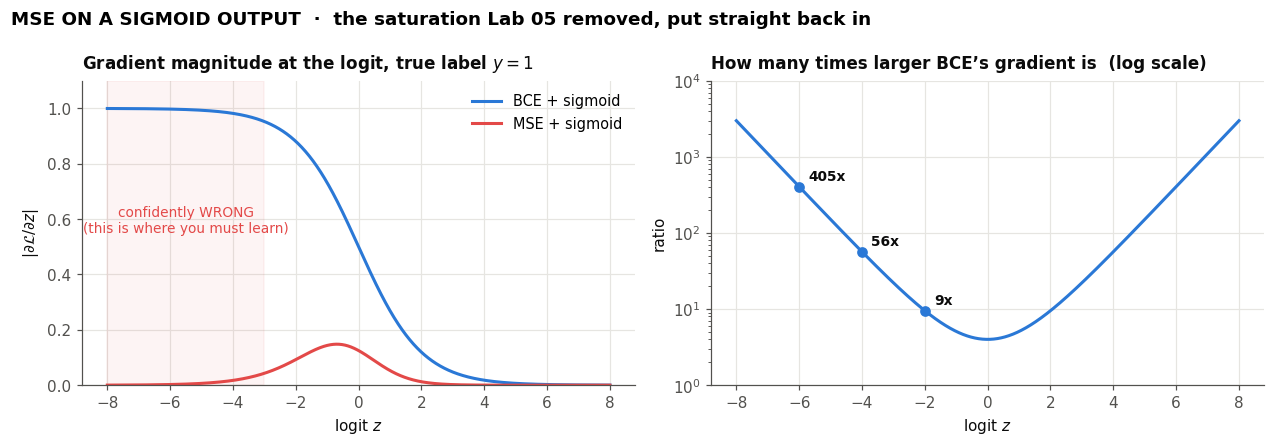

  logit z         p    BCE grad    MSE grad       ratio
       -8   0.00034     0.99966   0.0003351       2,983x
       -6   0.00247     0.99753   0.0024604         405x
       -4   0.01799     0.98201   0.0173450          57x
       -2   0.11920     0.88080   0.0924780          10x
        0   0.50000     0.50000   0.1250000           4x
        2   0.88080     0.11920   0.0125155          10x

A network that is certain and wrong learns ~400x slower under MSE. That is the bug.


In [9]:
# --- 8.1 Gradient at the logit: BCE vs MSE, target y = 1 -------------------
Z = np.linspace(-8, 8, 1200)
p = sigmoid(Z)
g_bce = p - 1.0                       # dL/dz  for BCE
g_mse = (p - 1.0) * p * (1 - p)       # dL/dz  for MSE on the sigmoid output

fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.1))

ax[0].plot(Z, np.abs(g_bce), color=C['ce'],  label='BCE + sigmoid')
ax[0].plot(Z, np.abs(g_mse), color=BAD,      label='MSE + sigmoid')
ax[0].axvspan(-8, -3, color=BAD, alpha=.06)
ax[0].annotate('confidently WRONG\n(this is where you must learn)', (-5.5, .55),
               color=BAD, fontsize=9, ha='center')
ax[0].set_ylim(0, 1.1); ax[0].legend(fontsize=9.5)
style(ax[0], 'Gradient magnitude at the logit, true label $y=1$',
      xlabel='logit $z$', ylabel=r'$|\partial\mathcal{L}/\partial z|$', zero=False)

ratio = np.abs(g_bce) / np.maximum(np.abs(g_mse), 1e-300)
ax[1].semilogy(Z, ratio, color=C['ce'])
for zz in (-6, -4, -2):
    i = np.abs(Z - zz).argmin()
    ax[1].plot([zz], [ratio[i]], 'o', ms=6, color=C['ce'])
    ax[1].annotate(f'{ratio[i]:,.0f}x', (zz, ratio[i]), (6, 4), textcoords='offset points',
                   fontsize=9, color=INK, fontweight='bold')
ax[1].set_ylim(1, 1e4)
style(ax[1], 'How many times larger BCE’s gradient is  (log scale)',
      xlabel='logit $z$', ylabel='ratio', zero=False)

fig.suptitle('MSE ON A SIGMOID OUTPUT  ·  the saturation Lab 05 removed, put straight back in',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f'{"logit z":>9}{"p":>10}{"BCE grad":>12}{"MSE grad":>12}{"ratio":>12}')
for zz in (-8, -6, -4, -2, 0, 2):
    pv = sigmoid(np.array([float(zz)]))[0]
    gb, gm = abs(pv - 1), abs((pv - 1) * pv * (1 - pv))
    print(f'{zz:>9}{pv:>10.5f}{gb:>12.5f}{gm:>12.7f}{gb / gm:>12,.0f}x')
print('\nA network that is certain and wrong learns ~400x slower under MSE. That is the bug.')

---
## 9 · Categorical cross-entropy, sparse CE, and label smoothing

$$\mathcal{L}_{\text{CCE}} = -\sum_{i=1}^{K} y_i \log p_i
\;\;\xrightarrow{\;\text{one-hot}\;}\;\; -\log p_{\text{true}}$$

With a one-hot target the sum has **one** surviving term. All the other classes
influence the loss only through the softmax normalisation — which is exactly the
competition from Lab 05 §5.2.

### 9.1 `categorical` vs `sparse_categorical`

Identical mathematics, different label plumbing:

| | target format | Keras |
|---|---|---|
| categorical CE | one-hot `[0,0,1,0]` | `categorical_crossentropy` |
| sparse categorical CE | integer `2` | `sparse_categorical_crossentropy` |

Use **sparse** — no need to materialise a 50,000-wide one-hot per token. The
only reason to use one-hot is if your targets are genuinely soft (§9.2, §10).

### 9.2 Label smoothing

Replace the hard target with a slightly softened one:

$$y_i^{\text{LS}} = (1-\varepsilon)\,y_i + \frac{\varepsilon}{K}$$

**Why.** A one-hot target asks for $p_{\text{true}} = 1$ exactly, which needs a
logit gap of $\infty$. The network chases it, weights grow without bound, and the
model becomes overconfident and badly calibrated. Smoothing sets a **finite**
optimum: with ε and K classes the best achievable target probability is
$1-\varepsilon+\varepsilon/K$, reached at a **finite** logit gap — so the weights
stop growing. Typical ε = 0.1.

**Cost.** Deliberately worse probabilities (they are capped below 1), in exchange
for better generalisation and calibration. Do not use it when the calibrated
probability itself is the product.

  epsilon   best p_true   optimal gap
     0.00        1.0000           inf
     0.05        0.9550          5.26
     0.10        0.9100          4.51
     0.20        0.8200          3.71


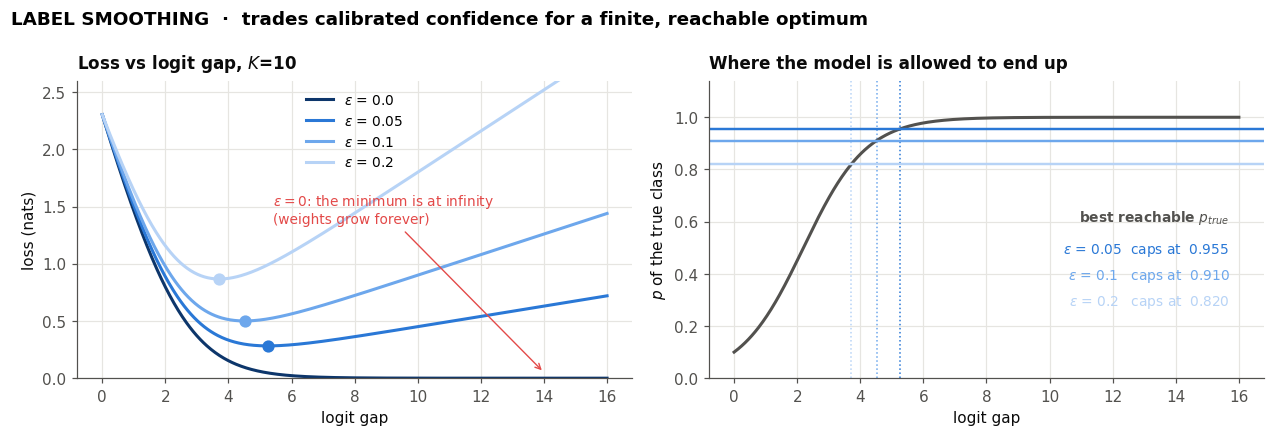

In [10]:
# --- 9.1 Label smoothing puts a finite optimum where there was none --------
K = 10
gaps = np.linspace(0, 16, 600)            # logit gap between true class and the rest

def loss_at_gap(gap, eps):
    z = np.zeros(K); z[0] = gap           # true class = 0
    p = softmax(z)
    t = np.full(K, eps / K); t[0] += 1 - eps
    return -(t * np.log(np.clip(p, EPS, 1))).sum(), p[0]

fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.0))
shades = ['#0d366b', '#2a78d6', '#6da7ec', '#b7d3f6']
print(f'{"epsilon":>9}{"best p_true":>14}{"optimal gap":>14}')
for eps, col in zip([0.0, 0.05, 0.1, 0.2], shades):
    L = np.array([loss_at_gap(g, eps)[0] for g in gaps])
    ax[0].plot(gaps, L, color=col, label=f'$\\varepsilon$ = {eps}')
    j = L.argmin()
    if eps > 0:
        ax[0].plot(gaps[j], L[j], 'o', ms=7, color=col)
        ax[1].axvline(gaps[j], color=col, ls=':', lw=1)
    best_p = 1 - eps + eps / K
    print(f'{eps:>9.2f}{best_p:>14.4f}{gaps[j] if eps > 0 else np.inf:>14.2f}')
ax[0].set_ylim(0, 2.6); ax[0].legend(fontsize=9)
ax[0].annotate('$\\varepsilon=0$: the minimum is at infinity\n(weights grow forever)',
               (14, .05), (5.4, 1.35), color=BAD, fontsize=9,
               arrowprops=dict(arrowstyle='->', color=BAD, lw=.9))
style(ax[0], 'Loss vs logit gap, $K$=10', xlabel='logit gap', ylabel='loss (nats)', zero=False)

ax[1].plot(gaps, [loss_at_gap(g, 0)[1] for g in gaps], color=MUTE)
ax[1].text(15.7, .60, 'best reachable $p_{true}$', ha='right', fontsize=9,
           color=MUTE, fontweight='bold')
for eps, col, ytxt in zip([0.05, 0.1, 0.2], shades[1:], [.48, .38, .28]):
    ax[1].axhline(1 - eps + eps / K, color=col, lw=1.6)
    ax[1].text(15.7, ytxt, f'$\\varepsilon$ = {eps:<4}  caps at  {1 - eps + eps / K:.3f}',
               ha='right', fontsize=9, color=col)
ax[1].set_ylim(0, 1.14)
style(ax[1], 'Where the model is allowed to end up',
      xlabel='logit gap', ylabel='$p$ of the true class', zero=False)

fig.suptitle('LABEL SMOOTHING  ·  trades calibrated confidence for a finite, reachable optimum',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

---
## 10 · KL divergence vs cross-entropy

$$\underbrace{H(p,q)}_{\text{cross-entropy}} = \underbrace{H(p)}_{\text{entropy of the TARGET}} + \underbrace{D_{\mathrm{KL}}(p\,\|\,q)}_{\text{divergence}}$$

**With one-hot targets, $H(p) = 0$.** Cross-entropy and KL are then numerically
identical, and minimising either is the same optimisation. That is why nobody
distinguishes them in ordinary classification.

**With soft targets they differ by the constant $H(p)$.** The constant has zero
gradient — so training is unaffected — but it changes the number you report:

- $D_{\mathrm{KL}} \to 0$ when the match is perfect. **Interpretable.**
- $H(p,q) \to H(p) > 0$ at a perfect match. Looks like a floor you cannot beat.

**So:** use KL whenever the targets are distributions — knowledge distillation
(Lab 05 §5.4), VAEs, policy regularisation, soft labels from an ensemble — so
that "0 means perfect" stays true.

  target     H(p)   CE(p,q)   KL(p||q)     H+KL
    hard   0.0000    0.4212     0.4212   0.4212
    soft   0.8261    0.8512     0.0251   0.8512

what each reports at a PERFECT match (q == p):
    hard   CE = 0.0000   KL = 0.0000
    soft   CE = 0.8261   KL = 0.0000   <- CE has a floor of H(p)


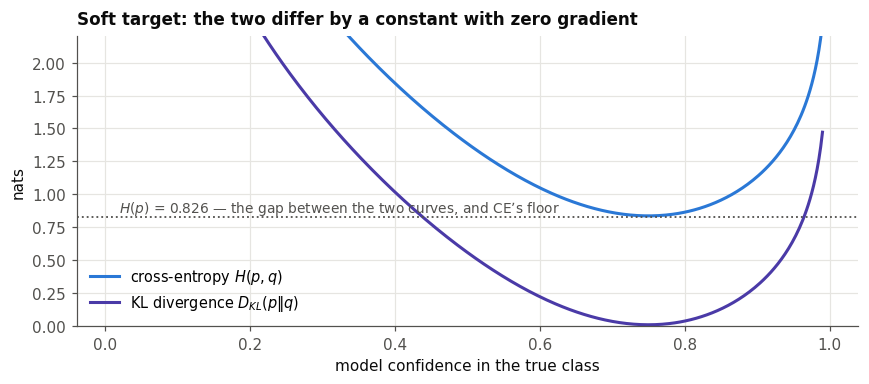

In [11]:
# --- 10.1 CE = H(p) + KL, verified on hard and soft targets ----------------
def H(p):            return max(0.0, -(p * np.log(np.clip(p, EPS, 1))).sum())
def CE(p, q):        return max(0.0, -(p * np.log(np.clip(q, EPS, 1))).sum())
def KL(p, q):        return (p * np.log(np.clip(p, EPS, 1) / np.clip(q, EPS, 1))).sum()

hard = np.array([0., 0., 1., 0.])
soft = np.array([0.05, 0.10, 0.75, 0.10])     # e.g. a distillation teacher
q    = softmax(np.array([0.4, 0.9, 2.4, 0.6]))

print(f'{"target":>8}{"H(p)":>9}{"CE(p,q)":>10}{"KL(p||q)":>11}{"H+KL":>9}')
for name, t in [('hard', hard), ('soft', soft)]:
    print(f'{name:>8}{H(t):>9.4f}{CE(t, q):>10.4f}{KL(t, q):>11.4f}{H(t) + KL(t, q):>9.4f}')

print('\nwhat each reports at a PERFECT match (q == p):')
for name, t in [('hard', hard), ('soft', soft)]:
    print(f'{name:>8}   CE = {CE(t, t):.4f}   KL = {KL(t, t):.4f}'
          f'{"   <- CE has a floor of H(p)" if H(t) > 0 else ""}')

fig, ax = plt.subplots(figsize=(8.0, 3.6))
ts = np.linspace(0.01, 0.99, 400)
ce_v = [CE(soft, softmax(np.array([0., 0., np.log(t / (1 - t)) * 2, 0.]))) for t in ts]
kl_v = [KL(soft, softmax(np.array([0., 0., np.log(t / (1 - t)) * 2, 0.]))) for t in ts]
ax.plot(ts, ce_v, color=C['ce'], label='cross-entropy $H(p,q)$')
ax.plot(ts, kl_v, color=C['kl'],  label='KL divergence $D_{KL}(p\\|q)$')
ax.axhline(H(soft), color=MUTE, ls=':', lw=1.2)
ax.annotate(f'$H(p)$ = {H(soft):.3f} — the gap between the two curves, and CE’s floor',
            (0.02, H(soft) + .04), fontsize=9, color=MUTE)
ax.set_ylim(0, 2.2); ax.legend(fontsize=9.5)
style(ax, 'Soft target: the two differ by a constant with zero gradient',
      xlabel='model confidence in the true class', ylabel='nats', zero=False)
fig.tight_layout(); plt.show()

---
## 11 · Hinge loss — when you want a margin, not a probability

With labels $y\in\{-1,+1\}$ and a raw score $f(x)$, define the **margin**
$m = y\,f(x)$ — positive means correct, and its size is how comfortably correct.

$$\boxed{\;\mathcal{L}_{\text{hinge}} = \max(0,\; 1 - m)\;}$$

### 11.1 The property nothing else has: it reaches exactly zero

Once $m \ge 1$ — correct **with margin** — the loss is **exactly 0** and the
gradient is **exactly 0**. That point stops contributing entirely. Only the points
near or inside the margin push on the weights; in an SVM those are precisely the
**support vectors**.

Contrast with logistic/BCE, which is $\log(1+e^{-m})$: always positive, always a
non-zero gradient. A cleanly-classified point *still* asks for a slightly bigger
logit, forever. That is why cross-entropy keeps inflating confidence (and why
label smoothing exists), and why hinge does not.

### 11.2 What you give up

Hinge produces a **score**, not a probability — there is no $p$ to calibrate or
threshold meaningfully. If a downstream system needs "70% confident", hinge is
the wrong loss. Squared hinge $\max(0,1-m)^2$ is its smooth cousin: differentiable
everywhere, but it hands outliers a quadratic penalty again.

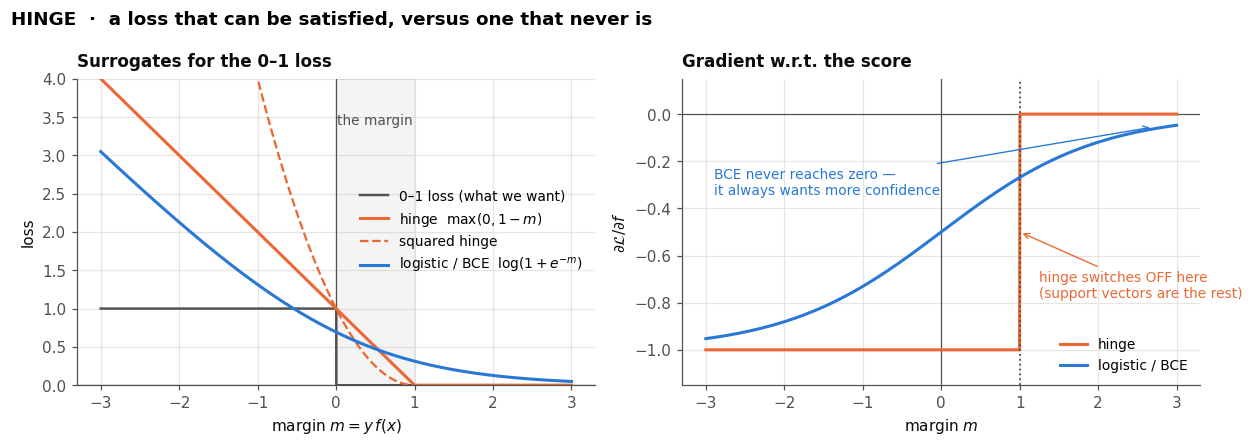

  margin    0-1    hinge   sq hinge   logistic
    -2.0      1    3.000      9.000     2.1269
    -0.5      1    1.500      2.250     0.9741
     0.0      0    1.000      1.000     0.6931
     0.5      0    0.500      0.250     0.4741
     1.0      0    0.000      0.000     0.3133
     2.0      0    0.000      0.000     0.1269
     5.0      0    0.000      0.000     0.0067

At margin 5 the hinge is done (0.000). Logistic still charges 0.0067 and still pulls.


In [12]:
# --- 11.1 Hinge vs logistic vs 0-1, on the margin axis ---------------------
M = np.linspace(-3, 3, 1200)
zero_one = (M < 0).astype(float)
logistic = np.log1p(np.exp(-M))                  # BCE written in margin form

fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.1))

ax[0].step(M, zero_one, where='post', color=MUTE, lw=1.6, label='0–1 loss (what we want)')
ax[0].plot(M, hinge(M),    color=C['hinge'], label='hinge  $\\max(0,1-m)$')
ax[0].plot(M, sq_hinge(M), color=C['hinge'], ls='--', lw=1.5, label='squared hinge')
ax[0].plot(M, logistic,    color=C['ce'],    label='logistic / BCE  $\\log(1+e^{-m})$')
ax[0].axvspan(0, 1, color=MUTE, alpha=.06)
ax[0].annotate('the margin', (0.5, 3.4), color=MUTE, fontsize=9, ha='center')
ax[0].set_ylim(0, 4); ax[0].legend(fontsize=9)
style(ax[0], 'Surrogates for the 0–1 loss', 
      xlabel='margin $m = y\\,f(x)$', ylabel='loss')

ax[1].plot(M, np.where(M < 1, -1.0, 0.0), color=C['hinge'], label='hinge')
ax[1].plot(M, -sigmoid(-M), color=C['ce'], label='logistic / BCE')
ax[1].axvline(1, color=MUTE, ls=':', lw=1.2)
ax[1].annotate('hinge switches OFF here\n(support vectors are the rest)', (1, -.5), (1.25, -.78),
               color=C['hinge'], fontsize=9,
               arrowprops=dict(arrowstyle='->', color=C['hinge'], lw=.9))
ax[1].annotate('BCE never reaches zero —\nit always wants more confidence', (2.7, -.055), (-2.9, -.34),
               color=C['ce'], fontsize=9, ha='left',
               arrowprops=dict(arrowstyle='->', color=C['ce'], lw=.9))
ax[1].set_ylim(-1.15, .15); ax[1].legend(fontsize=9, loc='lower right')
style(ax[1], 'Gradient w.r.t. the score', xlabel='margin $m$', ylabel=r'$\partial\mathcal{L}/\partial f$')

fig.suptitle('HINGE  ·  a loss that can be satisfied, versus one that never is',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f'{"margin":>8}{"0-1":>7}{"hinge":>9}{"sq hinge":>11}{"logistic":>11}')
for m in (-2, -0.5, 0, 0.5, 1.0, 2.0, 5.0):
    v = np.array([float(m)])
    print(f'{m:>8.1f}{float(m < 0):>7.0f}{hinge(v)[0]:>9.3f}{sq_hinge(v)[0]:>11.3f}{np.log1p(np.exp(-v))[0]:>11.4f}')
print('\nAt margin 5 the hinge is done (0.000). Logistic still charges 0.0067 and still pulls.')

---
## 12 · Focal loss — when one class drowns out the other

$$\boxed{\;\mathcal{L}_{\text{focal}} = -\alpha\,(1-p_t)^{\gamma}\log p_t\;}
\qquad p_t = \begin{cases}p & y=1\\ 1-p & y=0\end{cases}$$

Cross-entropy with a **modulating factor** $(1-p_t)^\gamma$ bolted on. Set
$\gamma=0$ and you get plain CE back.

### 12.1 The problem it solves

Dense object detection, fraud, rare disease — 99% of samples are easy negatives
the model already gets right at $p_t\approx0.95$. Each contributes a *small* loss
(0.05 nats), but there are **tens of thousands of them**, so in aggregate they
own the gradient and the rare positives are never learned.

Focal loss down-weights what is already correct:

| $p_t$ | CE loss | ×(1−p)² factor | focal loss | shrunk by |
|---|---|---|---|---|
| 0.95 (easy) | 0.051 | 0.0025 | 0.00013 | **400×** |
| 0.50 | 0.693 | 0.25 | 0.173 | 4× |
| 0.10 (hard) | 2.303 | 0.81 | 1.865 | 1.2× |

Easy examples are suppressed ~400×; hard ones are essentially untouched. The
gradient budget moves to the samples that still need work. γ=2 is the standard
choice; α is a separate class-weight (use both — they fix different things).

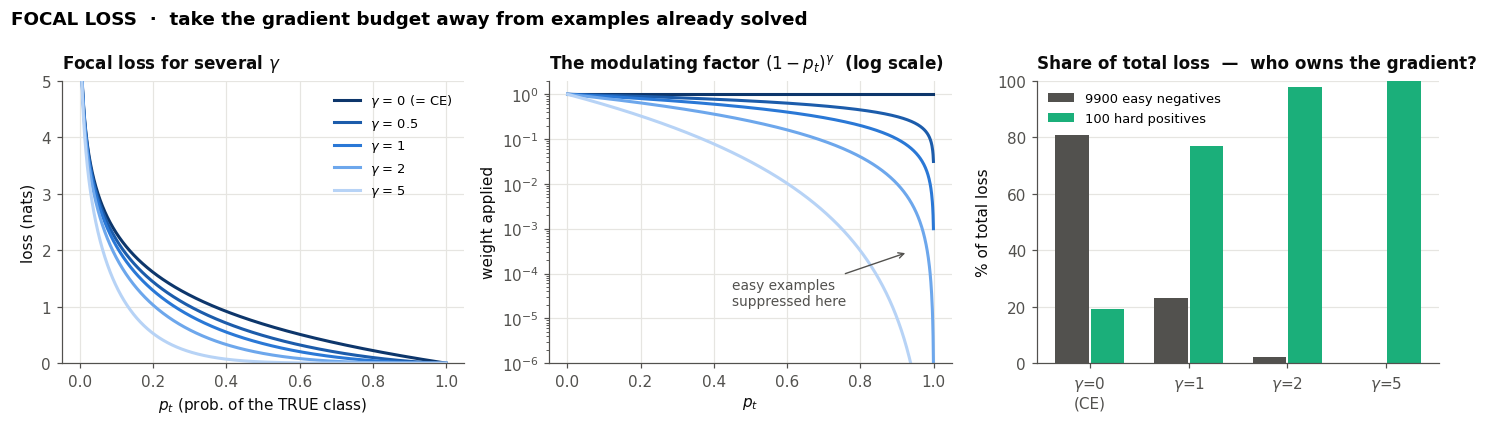

  gamma   easy share   hard share
      0        80.8%        19.2%
      1        23.2%        76.8%
      2         2.1%        97.9%
      5         0.0%       100.0%

Under plain CE the easy majority owns most of the loss. gamma=2 flips it.


In [13]:
# --- 12.1 Gamma sweep, and where the gradient budget actually goes ---------
pt = np.linspace(1e-3, 1 - 1e-3, 1000)

fig, ax = plt.subplots(1, 3, figsize=(13.2, 3.9))
shades = ['#0d366b', '#1c5cab', '#2a78d6', '#6da7ec', '#b7d3f6']
for g, col in zip([0, 0.5, 1, 2, 5], shades):
    ax[0].plot(pt, focal(pt, gamma=g), color=col, label=f'$\\gamma$ = {g}' + (' (= CE)' if g == 0 else ''))
ax[0].set_ylim(0, 5); ax[0].legend(fontsize=8.5)
style(ax[0], 'Focal loss for several $\\gamma$', xlabel='$p_t$ (prob. of the TRUE class)',
      ylabel='loss (nats)', zero=False)

for g, col in zip([0, 0.5, 1, 2, 5], shades):
    ax[1].semilogy(pt, (1 - pt) ** g, color=col)
ax[1].set_ylim(1e-6, 2)
ax[1].annotate('easy examples\nsuppressed here', (0.93, 3e-4), (0.45, 2e-5),
               color=MUTE, fontsize=9, arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
style(ax[1], r'The modulating factor $(1-p_t)^\gamma$  (log scale)',
      xlabel='$p_t$', ylabel='weight applied', zero=False)

# a realistic imbalanced batch: 9900 easy negatives + 100 hard positives
n_easy, n_hard = 9900, 100
pt_easy = np.full(n_easy, 0.95)
pt_hard = np.full(n_hard, 0.30)
rows = []
for g in [0, 1, 2, 5]:
    le = focal(pt_easy, gamma=g).sum()
    lh = focal(pt_hard, gamma=g).sum()
    rows.append((g, 100 * le / (le + lh), 100 * lh / (le + lh)))
gs = [r[0] for r in rows]
ax[2].bar(np.arange(len(rows)) - .18, [r[1] for r in rows], width=.34, color=MUTE, label='9900 easy negatives')
ax[2].bar(np.arange(len(rows)) + .18, [r[2] for r in rows], width=.34, color=C['focal'], label='100 hard positives')
ax[2].set_xticks(range(len(rows)), [f'$\\gamma$={g}' + ('\n(CE)' if g == 0 else '') for g in gs])
ax[2].set_ylim(0, 100); ax[2].legend(fontsize=8.5); ax[2].grid(axis='x', visible=False)
style(ax[2], 'Share of total loss  —  who owns the gradient?', ylabel='% of total loss', zero=False)

fig.suptitle('FOCAL LOSS  ·  take the gradient budget away from examples already solved',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f'{"gamma":>7}{"easy share":>13}{"hard share":>13}')
for g, e, h in rows:
    print(f'{g:>7}{e:>12.1f}%{h:>12.1f}%')
print('\nUnder plain CE the easy majority owns most of the loss. gamma=2 flips it.')

### 12.2 The question nobody asks: does it build a better model, or just move the threshold?

§12.1 showed focal loss flipping the loss share from 81% easy / 19% hard to
2% / 98%. That is dramatic. It is also **not the same claim** as "the model gets
better", and the two are routinely confused.

Run the next cell carefully. It trains the same logistic regression on 99:1 data
four ways and reports two very different kinds of number:

- **Average precision** and the **precision–recall curve** — threshold-free.
  These measure whether the model *ranks* the rare positives above the negatives,
  which is the only thing that counts as "a better model".
- **Recall and precision at $p>0.5$** — the operating point most people actually
  read off, and the one that moves wildly.

class balance: [5918   82] (1.4% positive)

                loss   avg prec   recall@.5   prec@.5   F1@.5   best F1   at thr


            plain CE      0.329       8.5%     87.5%    0.16      0.41     0.15


   weighted CE (x72)      0.315      70.7%      4.5%    0.08      0.41     0.84


         focal (γ=2)      0.328       8.5%     87.5%    0.16      0.41     0.32


    focal (γ=2, α=4)      0.327      17.1%     63.6%    0.27      0.42     0.43


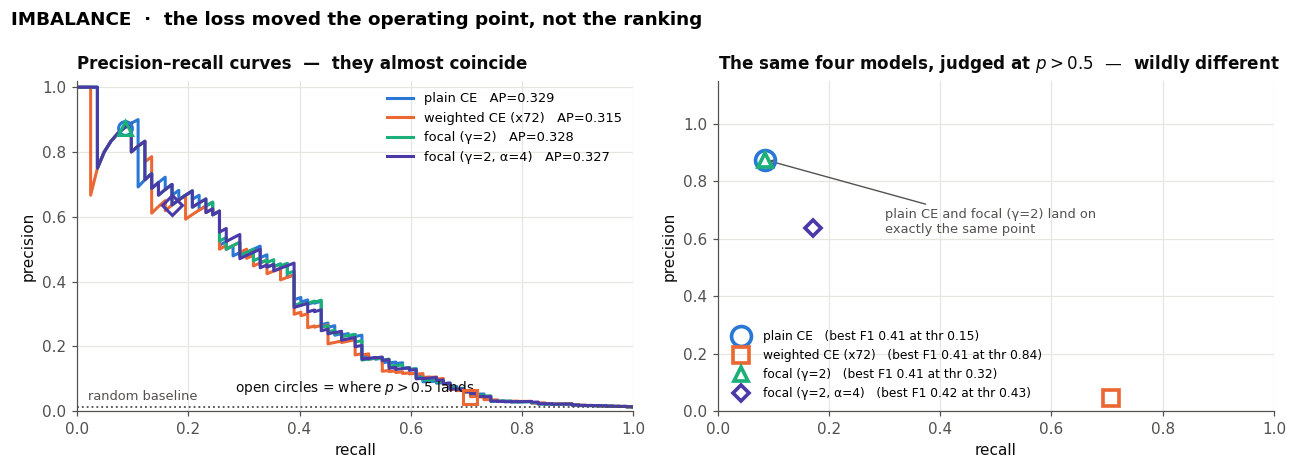

In [14]:
# --- 12.2 Imbalanced training: does the loss change the MODEL or the THRESHOLD?
from sklearn.datasets import make_classification
from sklearn.metrics import average_precision_score, precision_recall_curve

Xi, yi = make_classification(n_samples=6000, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, weights=[0.99], flip_y=0.01, random_state=4)
Xi = (Xi - Xi.mean(0)) / Xi.std(0)
Xi = np.c_[Xi, np.ones(len(Xi))]                       # bias column
print('class balance:', np.bincount(yi), f'({yi.mean():.1%} positive)')

def d_focal_dz(z, y, gamma=2.0, alpha=1.0):
    p  = sigmoid(z)
    s  = 2 * y - 1                                     # +1 / -1
    pt = np.clip(y * p + (1 - y) * (1 - p), EPS, 1 - EPS)
    dL_dpt = gamma * (1 - pt) ** (gamma - 1) * np.log(pt) - (1 - pt) ** gamma / pt
    return alpha * dL_dpt * s * p * (1 - p)

def train(grad_fn, steps=6000, lr=0.8):
    w = np.zeros(Xi.shape[1])
    for _ in range(steps):
        w -= lr * (Xi.T @ grad_fn(Xi @ w, yi) / len(Xi))
    return w

pos_w = (yi == 0).sum() / (yi == 1).sum()
runs = {
    'plain CE':                 (lambda z, y: sigmoid(z) - y,                                       C['ce']),
    f'weighted CE (x{pos_w:.0f})': (lambda z, y: (sigmoid(z) - y) * np.where(y == 1, pos_w, 1.0),   C['mae']),
    'focal (γ=2)':              (lambda z, y: d_focal_dz(z, y, 2.0),                                C['focal']),
    'focal (γ=2, α=4)':         (lambda z, y: d_focal_dz(z, y, 2.0, np.where(y == 1, 4.0, 1.0)),    C['logcosh']),
}

def best_f1(y, s):
    best, thr = 0.0, 0.5
    for t in np.linspace(0.01, 0.99, 197):
        pr = s > t
        tp = (pr & (y == 1)).sum(); fp = (pr & (y == 0)).sum(); fn = (~pr & (y == 1)).sum()
        r = tp / max(tp + fn, 1); pp = tp / max(tp + fp, 1)
        f = 2 * pp * r / max(pp + r, 1e-9)
        if f > best: best, thr = f, t
    return best, thr

fig, ax = plt.subplots(1, 2, figsize=(11.8, 4.3))
MARKS, k = ['o', 's', '^', 'D'], 0
print(f'\n{"loss":>20}{"avg prec":>11}{"recall@.5":>12}{"prec@.5":>10}{"F1@.5":>8}'
      f'{"best F1":>10}{"at thr":>9}')
for name, (gf, col) in runs.items():
    w = train(gf); s = sigmoid(Xi @ w)
    ap = average_precision_score(yi, s)
    pr = s > 0.5
    tp = (pr & (yi == 1)).sum(); fp = (pr & (yi == 0)).sum(); fn = (~pr & (yi == 1)).sum()
    rec = tp / max(tp + fn, 1); prec = tp / max(tp + fp, 1)
    f1  = 2 * prec * rec / max(prec + rec, 1e-9)
    bf1, bthr = best_f1(yi, s)
    print(f'{name:>20}{ap:>11.3f}{rec:>11.1%}{prec:>10.1%}{f1:>8.2f}{bf1:>10.2f}{bthr:>9.2f}')

    p_curve, r_curve, _ = precision_recall_curve(yi, s)
    ax[0].plot(r_curve, p_curve, color=col, lw=2, label=f'{name}   AP={ap:.3f}')
    ax[0].plot(rec, prec, MARKS[k], ms=9, mfc='none', mec=col, mew=2, zorder=5)
    ax[1].plot([rec], [prec], MARKS[k], ms=13 - 2 * k, mfc='none', mec=col, mew=2.4,
               zorder=5, label=f'{name}   (best F1 {bf1:.2f} at thr {bthr:.2f})')
    k += 1

ax[0].axhline(yi.mean(), color=MUTE, ls=':', lw=1.2)
ax[0].annotate('random baseline', (0.02, yi.mean() + .02), color=MUTE, fontsize=8.5)
ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02); ax[0].legend(fontsize=8.5, loc='upper right')
style(ax[0], 'Precision–recall curves  —  they almost coincide',
      xlabel='recall', ylabel='precision', zero=False)
ax[0].annotate('open circles = where $p>0.5$ lands', (0.5, 0.06), color=INK, fontsize=9, ha='center')

ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1.15); ax[1].legend(fontsize=8, loc='lower left')
ax[1].annotate('plain CE and focal (γ=2) land on\nexactly the same point', (0.085, 0.875),
               (0.30, 0.62), color=MUTE, fontsize=8.5,
               arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
style(ax[1], 'The same four models, judged at $p>0.5$  —  wildly different',
      xlabel='recall', ylabel='precision', zero=False)

fig.suptitle('IMBALANCE  ·  the loss moved the operating point, not the ranking',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

### 12.3 Read that result honestly

Average precision is **the same to within noise** for all four losses, and so is
the best achievable F1. The precision–recall curves lie almost on top of each
other. What changed enormously is **where the 0.5 threshold sits on that curve** —
recall at $p>0.5$ moves from 8% to 71% without the model having learned anything
new.

Three conclusions, and the third is the one that gets forgotten:

1. **Plain CE is not "broken" on imbalanced data.** It ranks fine. Its 98.7%
   accuracy and 8% recall are a *threshold* artefact, not a training failure.
   Accuracy was simply the wrong metric (§13.3).
2. **Class weights and focal-α mostly relocate the threshold.** If an operating
   point is all you want, **tune the threshold instead** — it is free, reversible,
   and does not require retraining.
3. **Focal loss still earns its place — in the regime it was designed for.** A
   dense detector evaluates $\sim10^5$ anchor boxes per image, almost all trivially
   background. There the easy examples swamp the *gradient* and the model genuinely
   underfits the rare class: the ranking itself improves. A 2-feature logistic
   regression has no such headroom: its ranking is limited by its two features
   (average precision about 0.33 whichever loss we use), not by which examples own
   the gradient, so there is nothing for focal loss to recover.

> **The habit to take away.** Before reaching for an exotic loss, check whether
> your problem is a *ranking* problem or a *threshold* problem. Plot the PR curve.
> If the curves coincide, the loss is not your bottleneck.

---
## 13 · Decision guide

### 13.1 Pick by task — the table to memorise

| Task | Output activation | **Loss** | Why |
|---|---|---|---|
| Regression, clean targets | linear | **MSE** | you want the conditional mean |
| Regression, noisy labels / heavy tails | linear | **Huber** (or MAE) | caps each point's gradient at δ |
| Regression, need a percentile | linear | **pinball** (τ) | targets the τ-quantile directly |
| Regression, counts ≥ 0 | exp or softplus (not ReLU) | **Poisson** | the right likelihood for counts; it takes $\log\hat y$, and ReLU can output exactly 0 |
| Binary classification | 1 × sigmoid | **BCE** | Bernoulli MLE; $\partial\mathcal{L}/\partial z = p-y$ |
| Binary, **99:1 imbalance** | 1 × sigmoid | **CE first, then focal/α** | check the PR curve first — often it is a threshold problem, not a loss problem (§12.3) |
| Multi-class, exclusive | softmax | **sparse categorical CE** | Categorical MLE; same cancellation |
| Multi-class, overconfident / poor calibration | softmax | **CE + label smoothing 0.1** | gives the optimum a finite location |
| Multi-**label** | K × sigmoid | **BCE summed over labels** | labels are independent |
| Soft / teacher targets (distillation) | softmax + T | **KL** | "0 means perfect" stays true |
| Max-margin decision, probability not needed | linear score | **hinge** | zero loss once correct with margin |
| Segmentation with tiny foreground | sigmoid per pixel | **Dice / IoU** (+BCE) | optimises overlap, not pixel counts |

### 13.2 Five errors this lab exists to prevent

| Mistake | What actually happens | Fix |
|---|---|---|
| **MSE on a sigmoid/softmax output** | ~400× less gradient exactly when confidently wrong (§8) | cross-entropy |
| **MSE on skewed targets when you needed the typical value** | model predicts the mean, which no sample resembles (§2) | MAE, or fix the question |
| **Blaming the loss for 99% accuracy / 8% recall** | CE ranked fine; 0.5 was simply the wrong threshold (§12.3) | tune the threshold; reach for focal/α only if the PR curve is genuinely worse |
| **Softmax applied twice** (softmax layer *and* `from_logits=True`) | gradients wrong and tiny | pass raw logits; let the loss do it |
| **Reporting CE on soft targets and expecting 0** | it bottoms out at $H(p)$, not 0 (§10) | report KL |

### 13.3 Two habits worth keeping

- **Loss ≠ metric.** Train on what is differentiable and well-conditioned (CE);
  report what the stakeholder cares about (F1, recall@precision, MAE in rupees).
  They can and should differ.
- **Read the derivative before you adopt a loss.** Every failure in this lab —
  outlier domination, MAE's bouncing, MSE+sigmoid, imbalance — is visible in the
  gradient plot before you train anything.

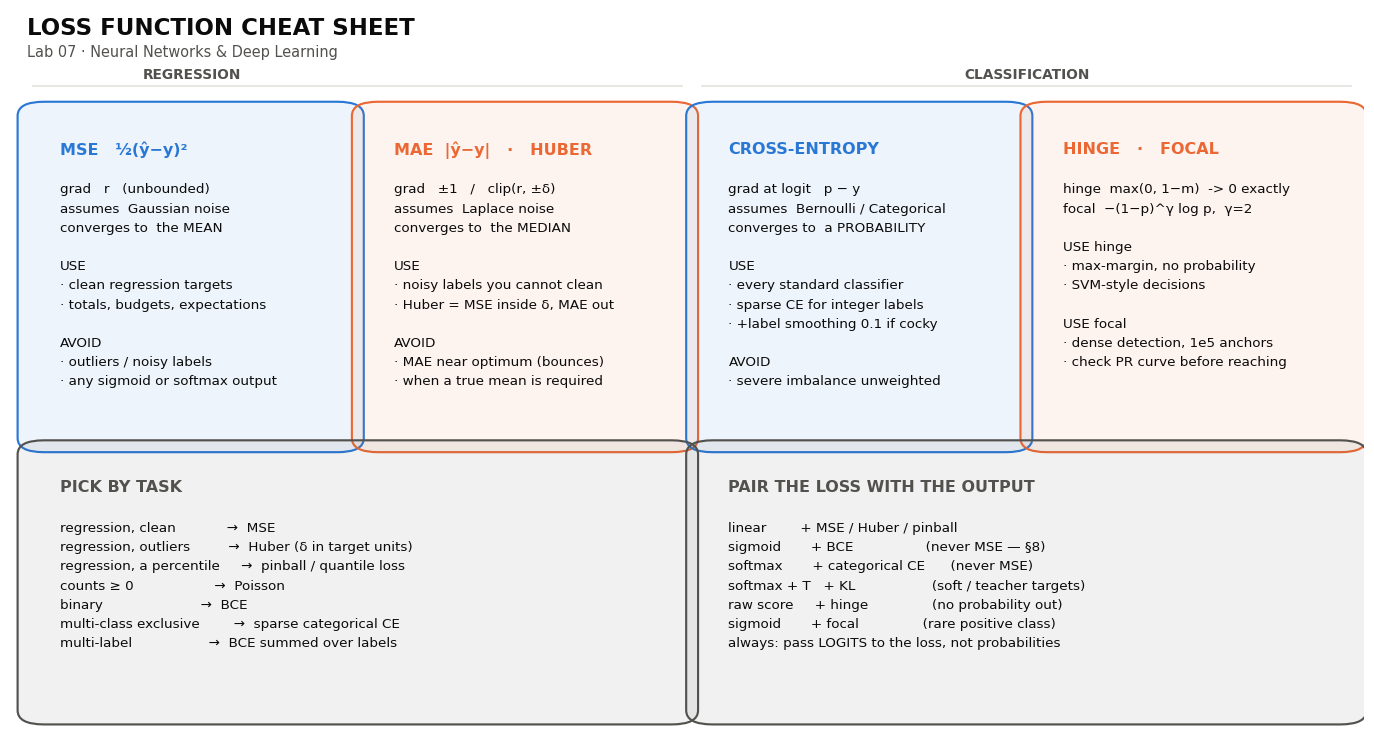

In [15]:
# --- 13.4 The cheat sheet, as a printable card ----------------------------
from matplotlib.patches import FancyBboxPatch

def card(ax, x, y, w, h, title, body, col):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.012,rounding_size=0.02',
                                linewidth=1.4, edgecolor=col, facecolor=col + '14'))
    ax.text(x + .020, y + h - .045, title, fontsize=10.5, fontweight='bold', color=col, va='top')
    ax.text(x + .020, y + h - .105, body, fontsize=8.8, color=INK, va='top', linespacing=1.62)

fig, ax = plt.subplots(figsize=(12.6, 6.9))
ax.set_xlim(-.012, 1.012); ax.set_ylim(-.02, 1.02); ax.axis('off')
ax.text(0, 1.012, 'LOSS FUNCTION CHEAT SHEET', fontsize=15, fontweight='bold', color=INK, va='top')
ax.text(0, .972, 'Lab 07 · Neural Networks & Deep Learning', fontsize=9.5, color=MUTE, va='top')
ax.text(0.125, .918, 'REGRESSION', fontsize=9, color=MUTE, ha='center', va='bottom',
        fontweight='bold')
ax.text(0.757, .918, 'CLASSIFICATION', fontsize=9, color=MUTE, ha='center', va='bottom',
        fontweight='bold')
ax.plot([0.005, 0.496], [.912, .912], color=GRID, lw=1.2)
ax.plot([0.511, 1.002], [.912, .912], color=GRID, lw=1.2)

card(ax, 0.005, .400, .238, .478, 'MSE   ½(ŷ−y)²',
     "grad   r   (unbounded)\n"
     "assumes  Gaussian noise\n"
     "converges to  the MEAN\n\n"
     'USE\n'
     '· clean regression targets\n'
     '· totals, budgets, expectations\n\n'
     'AVOID\n'
     '· outliers / noisy labels\n'
     '· any sigmoid or softmax output', C['mse'])

card(ax, 0.258, .400, .238, .478, 'MAE  |ŷ−y|   ·   HUBER',
     "grad   ±1   /   clip(r, ±δ)\n"
     "assumes  Laplace noise\n"
     "converges to  the MEDIAN\n\n"
     'USE\n'
     '· noisy labels you cannot clean\n'
     '· Huber = MSE inside δ, MAE out\n\n'
     'AVOID\n'
     '· MAE near optimum (bounces)\n'
     '· when a true mean is required', C['mae'])

card(ax, 0.511, .400, .238, .478, 'CROSS-ENTROPY',
     "grad at logit   p − y\n"
     "assumes  Bernoulli / Categorical\n"
     "converges to  a PROBABILITY\n\n"
     'USE\n'
     '· every standard classifier\n'
     '· sparse CE for integer labels\n'
     '· +label smoothing 0.1 if cocky\n\n'
     'AVOID\n'
     '· severe imbalance unweighted', C['ce'])

card(ax, 0.764, .400, .238, .478, 'HINGE   ·   FOCAL',
     "hinge  max(0, 1−m)  -> 0 exactly\n"
     "focal  −(1−p)^γ log p,  γ=2\n\n"
     'USE hinge\n'
     '· max-margin, no probability\n'
     '· SVM-style decisions\n\n'
     'USE focal\n'
     '· dense detection, 1e5 anchors\n'
     '· check PR curve before reaching', C['hinge'])

card(ax, 0.005, .010, .491, .383, 'PICK BY TASK',
     'regression, clean            →  MSE\n'
     'regression, outliers         →  Huber (δ in target units)\n'
     'regression, a percentile     →  pinball / quantile loss\n'
     'counts ≥ 0                   →  Poisson\n'
     'binary                       →  BCE\n'
     'multi-class exclusive        →  sparse categorical CE\n'
     'multi-label                  →  BCE summed over labels', MUTE)

card(ax, 0.511, .010, .491, .383, 'PAIR THE LOSS WITH THE OUTPUT',
     'linear        + MSE / Huber / pinball\n'
     'sigmoid       + BCE                 (never MSE — §8)\n'
     'softmax       + categorical CE      (never MSE)\n'
     'softmax + T   + KL                  (soft / teacher targets)\n'
     'raw score     + hinge               (no probability out)\n'
     'sigmoid       + focal               (rare positive class)\n'
     'always: pass LOGITS to the loss, not probabilities', MUTE)

fig.tight_layout(); plt.show()

---
## 14 · Exercises

**E1 — Derive.** Start from the Bernoulli likelihood $p^y(1-p)^{1-y}$, take
$-\log$, substitute $p=\sigma(z)$, and show $\partial\mathcal{L}/\partial z = p-y$.
Then do the same for MSE on $\sigma(z)$ and confirm the extra $\sigma'(z)$ factor
that §8 measures.

**E2 — Predict, then measure.** Before running: for a target with mean 4.2 and
median 3.1, what will an MSE-trained constant model output? An MAE-trained one?
Verify with the §2 cell by changing the distribution.

**E3 — Tune δ.** In §6, sweep Huber's δ from 0.1 to 20 and plot the fitted slope
against δ. At what δ does Huber become MSE for practical purposes? Explain the
answer in terms of the outlier's residual.

**E4 — Break the pairing.** Take the §12.2 logistic regression and train it with
**MSE on the sigmoid output** instead of BCE, same steps and learning rate. Plot
both loss curves. How many steps does MSE need to reach BCE's 100-step loss?

**E5 — Quantile regression.** Train three linear models on noisy data with
pinball loss at τ = 0.1, 0.5, 0.9. Plot all three lines. What fraction of points
falls below each? (It should match τ — that is the whole guarantee.)

**E6 — Focal derivative.** Verify `d_focal_dz` in §12.2 against a finite-difference
gradient, the way Lab 05 §5.7 verified $p-y$. Then set γ=0 and confirm it reduces
exactly to $p-y$.

**E7 — Back to the CIFAR-10 notebook** (`KidsLab05_CIFAR10_CNN.ipynb`). Retrain its CNN three ways: sparse categorical
CE, CE with label smoothing 0.1, and MSE on the softmax output. Report test
accuracy and the mean confidence of correct predictions. Explain the confidence
differences using §9.2 and §8.

---

### References

- Huber (1964), *Robust estimation of a location parameter* — the Huber loss.
- Koenker & Bassett (1978), *Regression quantiles* — the pinball loss.
- Rubinstein (1997) / Goodfellow et al. (2016) ch. 6 — cross-entropy as MLE.
- Szegedy et al. (2016), *Rethinking the Inception architecture* — label smoothing.
- Hinton, Vinyals & Dean (2015), *Distilling the knowledge in a neural network* — KL on soft targets.
- Cortes & Vapnik (1995), *Support-vector networks* — hinge loss and margins.
- Lin et al. (2017), *Focal loss for dense object detection* — focal loss.
- Milletari et al. (2016), *V-Net* — Dice loss for segmentation.

*Lab 07 · Neural Networks & Deep Learning · 2026*